In [1]:
pip install tensorflow-datasets

In [2]:
import tensorflow_datasets as tfds

In [3]:
import tensorflow as tf

In [4]:
!git clone https://github.com/ml4py/dataset-iiit-pet.git

Cloning into 'dataset-iiit-pet'...
remote: Enumerating objects: 18465, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 18465 (delta 1), reused 3 (delta 1), pack-reused 18460 (from 1)
Receiving objects: 100% (18465/18465), 772.55 MiB | 34.11 MiB/s, done.
Resolving deltas: 100% (3678/3678), done.
Updating files: 100% (18477/18477), done.


In [5]:
import pathlib

In [6]:
data_dir = pathlib.Path("/content/dataset-iiit-pet")

In [7]:
ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    image_size=(224, 224),
    batch_size=32
)

Found 14780 files belonging to 2 classes.


In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tanlikesmath/the-oxfordiiit-pet-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'the-oxfordiiit-pet-dataset' dataset.
Path to dataset files: /kaggle/input/the-oxfordiiit-pet-dataset


In [9]:
import os
import shutil

root = "/content/dataset-iiit-pet"   # change if needed
img_dir = os.path.join(root, "images")
ann_dir = os.path.join(root, "annotations")

# Output folders
train_dir = os.path.join(root, "train")
test_dir = os.path.join(root, "test")

os.makedirs(train_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

# --- Helper to copy files ---
def copy_split(txt_file, out_dir):
    with open(txt_file, "r") as f:
        for line in f:
            image_id = line.split()[0]   # e.g. "Abyssinian_100"
            src = os.path.join(img_dir, image_id + ".jpg")
            dst = os.path.join(out_dir, image_id + ".jpg")
            if os.path.exists(src):
                shutil.copy(src, dst)

# --- Copy trainval images ---
copy_split(os.path.join(ann_dir, "trainval.txt"), train_dir)

# --- Copy test images ---
copy_split(os.path.join(ann_dir, "test.txt"), test_dir)

print("Done! Train and test folders created.")

Done! Train and test folders created.


In [10]:
# Base directories - Updated for Oxford-IIIT Pet dataset
!pip install -q importlib_resources
import os
import glob
import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Dataset configuration
IMG_SIZE = (128, 128)
NUM_TRAIN_IMAGES = 500
NUM_TEST_IMAGES = 100
BATCH_SIZE = 4





# Preprocess images and segmentation masks
def preprocess(image, mask):
    image = tf.image.resize(
        image,
        IMG_SIZE
    )
    image = tf.cast(image, tf.float32) / 255.0

    mask = tf.image.resize(
        mask,
        IMG_SIZE,
        method="nearest"
    )

    # Foreground (pet) = 1; background and boundary = 0
    mask = tf.cast(tf.equal(mask, 1), tf.float32)

    return image, mask




print("Training and testing datasets are ready!")

# Optional: image generators (not required for tf.data pipelines)
img_gen = ImageDataGenerator()
mask_gen = ImageDataGenerator()

Training and testing datasets are ready!


In [11]:
def create_segmentation_generator(image_dir, mask_dir, batch_size=4):
    """
    Creates a generator that yields paired image and mask batches.
    Adapted for MedPlant dataset where images and masks are in separate directories.
    """

    # Get sorted list of image files
    image_files = sorted(
        glob.glob(os.path.join(image_dir, "*.jpg")) +
        glob.glob(os.path.join(image_dir, "*.png"))
    )

    if not image_files:
        raise ValueError(f"No images found in {image_dir}")

    # Verify corresponding masks exist
    mask_files = []
    for img_file in image_files:
        base_name = os.path.basename(img_file)
        mask_file = os.path.join(mask_dir, base_name)
        if os.path.exists(mask_file):
            mask_files.append(mask_file)
        else:
            print(f"Warning: No mask found for {img_file}")

    print(f"Found {len(image_files)} images and {len(mask_files)} masks")

    if len(mask_files) == 0:
        raise ValueError(f"No matching masks found in {mask_dir}")

    # Generator function
    def generator():
        idx = 0
        while True:
            batch_images = []
            batch_masks = []
            for _ in range(batch_size):
                if idx >= len(image_files):
                    idx = 0  # Loop back to start

                # Load image
                img = tf.keras.preprocessing.image.load_img(
                    image_files[idx],
                    target_size=(128, 128),
                    color_mode='grayscale'
                )

                img_array = tf.keras.preprocessing.image.img_to_array(img)
                img_array = img_array / 255.0  # Normalize
                batch_images.append(img_array)                # Load corresponding mask
                if idx < len(mask_files):
                    mask = tf.keras.preprocessing.image.load_img(
                        mask_files[idx],
                        target_size=(128, 128),
                        color_mode='grayscale'
                    )

                    mask_array = tf.keras.preprocessing.image.img_to_array(mask)
                    mask_array = mask_array / 255.0  # Normalize
                    batch_masks.append(mask_array)

                idx += 1

            yield (np.array(batch_images), np.array(batch_masks))

    return generator()

In [12]:
batch_size = 4

# Correct path configs
train_img_dir = "/content/dataset-iiit-pet/train"
test_img_dir = "/content/dataset-iiit-pet/test"
# Use the annotations trimaps directory
mask_dir = "/content/dataset-iiit-pet/annotations/trimaps"

def create_segmentation_generator_fixed(image_dir, mask_dir, batch_size=4):
    # Get sorted list of image files
    image_files = sorted(
        glob.glob(os.path.join(image_dir, "*.jpg")) +
        glob.glob(os.path.join(image_dir, "*.png"))
    )

    if not image_files:
        raise ValueError(f"No images found in {image_dir}")

    # Verify corresponding masks exist (handling different extension for trimaps, usually .png)
    mask_files = []
    valid_image_files = []
    for img_file in image_files:
        base_name_without_ext = os.path.splitext(os.path.basename(img_file))[0]
        # Try with .png (standard for trimaps) first, then original extension
        mask_file = os.path.join(mask_dir, base_name_without_ext + ".png")
        if not os.path.exists(mask_file):
            mask_file = os.path.join(mask_dir, base_name_without_ext + ".jpg")

        if os.path.exists(mask_file):
            mask_files.append(mask_file)
            valid_image_files.append(img_file)

    print(f"Found {len(valid_image_files)} matching image-mask pairs.")

    if len(mask_files) == 0:
        raise ValueError(f"No matching masks found in {mask_dir} using standard extensions.")

    def generator():
        idx = 0
        while True:
            batch_images = []
            batch_masks = []
            for _ in range(batch_size):
                if idx >= len(valid_image_files):
                    idx = 0  # Loop back

                # Load image
                img = tf.keras.preprocessing.image.load_img(
                    valid_image_files[idx],
                    target_size=(128, 128)
                )
                img_array = tf.keras.preprocessing.image.img_to_array(img) / 255.0
                batch_images.append(img_array)

                # Load mask
                mask = tf.keras.preprocessing.image.load_img(
                    mask_files[idx],
                    target_size=(128, 128),
                    color_mode='grayscale'
                )
                mask_array = tf.keras.preprocessing.image.img_to_array(mask)
                # Foreground (pet) pixel value in Oxford trimaps is 1
                mask_array = tf.cast(tf.equal(mask_array, 1.0), tf.float32)
                batch_masks.append(mask_array)

                idx += 1

            yield (np.array(batch_images), np.array(batch_masks))

    return generator()

# Initialize generators
train_gen = create_segmentation_generator_fixed(train_img_dir, mask_dir, batch_size=batch_size)
test_gen = create_segmentation_generator_fixed(test_img_dir, mask_dir, batch_size=batch_size)

print("Local train_gen and test_gen datasets are ready using fixed extension matching!")

Found 3680 matching image-mask pairs.
Found 3669 matching image-mask pairs.
Local train_gen and test_gen datasets are ready using fixed extension matching!


In [13]:
def build_unet(input_shape=(128, 128, 3)):
    inputs = Input(input_shape)

    c1 = Conv2D(64, 3, activation='relu', padding='same')(inputs)
    c1 = Conv2D(64, 3, activation='relu', padding='same')(c1)
    p1 = MaxPooling2D(2)(c1)

    c2 = Conv2D(128, 3, activation='relu', padding='same')(p1)
    c2 = Conv2D(128, 3, activation='relu', padding='same')(c2)
    p2 = MaxPooling2D(2)(c2)

    c3 = Conv2D(256, 3, activation='relu', padding='same')(p2)
    c3 = Conv2D(256, 3, activation='relu', padding='same')(c3)
    p3 = MaxPooling2D(2)(c3)

    c4 = Conv2D(512, 3, activation='relu', padding='same')(p3)
    c4 = Conv2D(512, 3, activation='relu', padding='same')(c4)
    p4 = MaxPooling2D(2)(c4)

    c5 = Conv2D(1024, 3, activation='relu', padding='same')(p4)
    c5 = Conv2D(1024, 3, activation='relu', padding='same')(c5)

    u6 = Conv2DTranspose(512, 2, strides=2, padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv2D(512, 3, activation='relu', padding='same')(u6)
    c6 = Conv2D(512, 3, activation='relu', padding='same')(c6)
    u6 = Conv2DTranspose(512, 2, strides=2, padding='same')(c5)
    u6 = concatenate([u6, c4])
    c6 = Conv2D(512, 3, activation='relu', padding='same')(u6)
    c6 = Conv2D(512, 3, activation='relu', padding='same')(c6)

    u7 = Conv2DTranspose(256, 2, strides=2, padding='same')(c6)
    u7 = concatenate([u7, c3])
    c7 = Conv2D(256, 3, activation='relu', padding='same')(u7)
    c7 = Conv2D(256, 3, activation='relu', padding='same')(c7)

    u8 = Conv2DTranspose(128, 2, strides=2, padding='same')(c7)
    u8 = concatenate([u8, c2])
    c8 = Conv2D(128, 3, activation='relu', padding='same')(u8)
    c8 = Conv2D(128, 3, activation='relu', padding='same')(c8)
    u9 = Conv2DTranspose(64, 2, strides=2, padding='same')(c8)
    u9 = concatenate([u9, c1])
    c9 = Conv2D(64, 3, activation='relu', padding='same')(u9)
    c9 = Conv2D(64, 3, activation='relu', padding='same')(c9)

    outputs = Conv2D(1, 1, activation='sigmoid')(c9)

    model = Model(inputs, outputs)
    return model

In [14]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Conv2DTranspose, concatenate
from tensorflow.keras.models import Model
from tensorflow.keras import backend as K

# Define custom metrics
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def jaccard_index(y_true, y_pred, smooth=1e-6):
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    total = K.sum(y_true_f) + K.sum(y_pred_f)
    union = total - intersection
    return (intersection + smooth) / (union + smooth)

# Instantiate the model
model = build_unet()

# Compile the model with the defined metrics
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss="binary_crossentropy",
    metrics=[dice_coef, jaccard_index]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │     36,928 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    590,080 │ conv2d_4[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │  1,180,160 │ max_pooling2d_2[… │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │  2,359,808 │ conv2d_6[0][0]    │
│                     │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 512) │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 8, 8,      │  4,719,616 │ max_pooling2d_3[… │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8,      │  9,438,208 │ conv2d_8[0][0]    │
│                     │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 16, 16,    │  2,097,664 │ conv2d_9[0][0]    │
│ (Conv2DTranspose)   │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 16, 16,    │          0 │ conv2d_transpose

 Total params: 31,031,745 (118.38 MB)

 Trainable params: 31,031,745 (118.38 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
steps_train = 100
steps_test = 6

history = model.fit(
    train_gen,
    steps_per_epoch=steps_train,
    validation_data=test_gen,
    validation_steps=steps_test,
    epochs=20
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 125ms/step - dice_coef: 0.6228 - jaccard_index: 0.4551 - loss: 0.3687 - val_dice_coef: 0.4880 - val_jaccard_index: 0.3252 - val_loss: 0.4678
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 127ms/step - dice_coef: 0.5311 - jaccard_index: 0.3669 - loss: 0.3706 - val_dice_coef: 0.3923 - val_jaccard_index: 0.2456 - val_loss: 0.4991
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 125ms/step - dice_coef: 0.5647 - jaccard_index: 0.3963 - loss: 0.3862 - val_dice_coef: 0.5396 - val_jaccard_index: 0.3737 - val_loss: 0.4212
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 127ms/step - dice_coef: 0.5897 - jaccard_index: 0.4216 - loss: 0.3861 - val_dice_coef: 0.6377 - val_jaccard_index: 0.4759 - val_loss: 0.3861
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 126ms/step - dice_coef: 0.6089 - jaccard_index: 0.4425 - loss: 0.4280 - val_dice_coef: 0.5147 - val_jaccard_index: 0.3488 - val_loss: 0.4557
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 125ms/step - dice_coef: 0.5901 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step


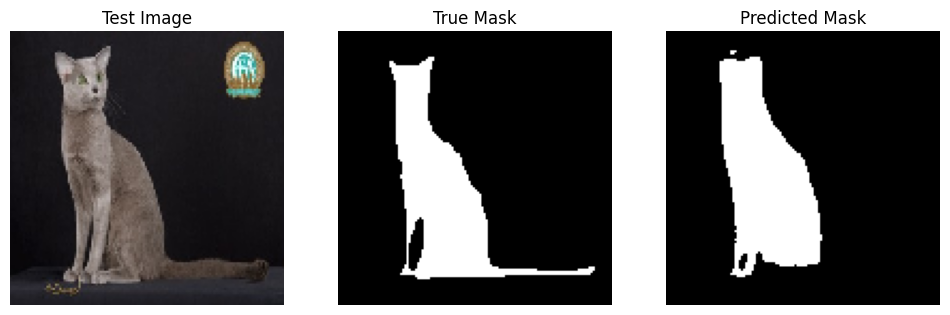

In [18]:
import matplotlib.pyplot as plt
import numpy as np

# Get a batch of images and masks from the test generator
test_imgs, test_masks = next(test_gen)

# Generate predictions for the batch
preds = model.predict(test_imgs)
# Threshold the predictions to binary masks
pred_bin = (preds > 0.5).astype(np.float32)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.title("Test Image")
# Display the first image in the batch
plt.imshow(test_imgs[0])
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title("True Mask")
# Display the first true mask in the batch
plt.imshow(test_masks[0].squeeze(), cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title("Predicted Mask")
# Display the first predicted binary mask
plt.imshow(pred_bin[0].squeeze(), cmap='gray')
plt.axis('off')

plt.show()